# Odometry Exercise 2 — plotting translation data

Load a timestamped translation log, plot what the encoders and local odometry reported, and compare final odometry displacement with your independent physical-distance measurements.

This notebook is an introduction to plotting odometry data. Start with the supplied synthetic example so that you can see what each cell produces. The example is not evidence about your robot. When you are ready, change the settings in the **Use your own data** cell and run the notebook again.


In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
rng = np.random.default_rng(2026)


## 1. Use the example or your own data

Leave `USE_EXAMPLE_DATA` set to `True` on your first run. To use your measurements, upload the CSV exported from the Serial Monitor, set `USE_EXAMPLE_DATA = False`, and enter its filename. This is the main cell you need to edit.


In [7]:
USE_EXAMPLE_DATA = False
CSV_FILENAME = "radius.csv"

print("Using:", "synthetic example" if USE_EXAMPLE_DATA else CSV_FILENAME)


Using: radius.csv


## 2. Create the small synthetic example

Run this cell when using the example. You do not need to understand or edit the generation code. Its columns match the translation log in Exercise 2.


In [8]:
example_rows = []
example_conditions = [
    (1, 100, 96, 1.0),
    (2, 200, 191, -2.0),
    (3, -150, -144, 1.5),
    (4, 300, 287, -3.0),
]

for trial_num, command_mm, final_x_mm, sideways_mm in example_conditions:
    for sample_num, progress in enumerate(np.linspace(0, 1, 31)):
        example_rows.append({
            "test_name": "translation",
            "trial_num": trial_num,
            "commanded_distance_mm": command_mm,
            "sample_time_ms": 1000 * trial_num + 50 * sample_num,
            "left_encoder_count": round(progress * final_x_mm * 3.55),
            "right_encoder_count": round(progress * final_x_mm * 3.58),
            "odometry_x_mm": progress * final_x_mm,
            "odometry_y_mm": sideways_mm * np.sin(np.pi * progress),
            "odometry_theta_rad": 0.02 * np.sin(np.pi * progress),
        })

example_data = pd.DataFrame(example_rows)


## 3. Load and preview the selected data

When `USE_EXAMPLE_DATA` is false, `pd.read_csv(...)` reads your file. The final line displays its first five rows. Check that they look like the rows you saved before continuing.


In [9]:
if USE_EXAMPLE_DATA:
    data = example_data.copy()
else:
    data = pd.read_csv(CSV_FILENAME)

data.head()


,test_name,trial_num,commanded_distance_mm,sample_time_ms,left_encoder_count,right_encoder_count,odometry_x_mm,odometry_y_mm,odometry_theta_rad
0,translation1,1,100,6130,0,0,0.00,0.0,0.0
1,translation1,1,100,6140,0,0,0.00,0.0,0.0
2,translation1,1,100,6150,1,1,0.28,0.0,0.0
3,translation1,1,100,6160,4,3,0.98,0.0,-0.0
4,translation1,1,100,6170,4,4,1.12,-0.0,-0.0


## 4. Calculate elapsed time

Each trial may begin at a different StampC3 timestamp. Subtracting the first timestamp in each trial makes every plot begin at zero seconds.


In [10]:

data = data.loc[
    data["test_name"].isin([
        "translation1",
        "translation2",
        "translation3",
        "translation4"
    ])
].copy()

data = data.sort_values(["trial_num", "sample_time_ms"])

data["elapsed_s"] = (
    data["sample_time_ms"]
    - data.groupby("trial_num")["sample_time_ms"].transform("first")
) / 1000

data["trial_label"] = "Trial " + data["trial_num"].astype(str)

data[["trial_num", "sample_time_ms", "elapsed_s"]].head()


,trial_num,sample_time_ms,elapsed_s
0,1,6130,0.00
1,1,6140,0.01
2,1,6150,0.02
3,1,6160,0.03
4,1,6170,0.04


## 5. Plot both encoder counts

The left and right traces should be read as recorded wheel motion, not as an independent measurement of physical distance. Look at their directions and whether they remain similar during each translation.


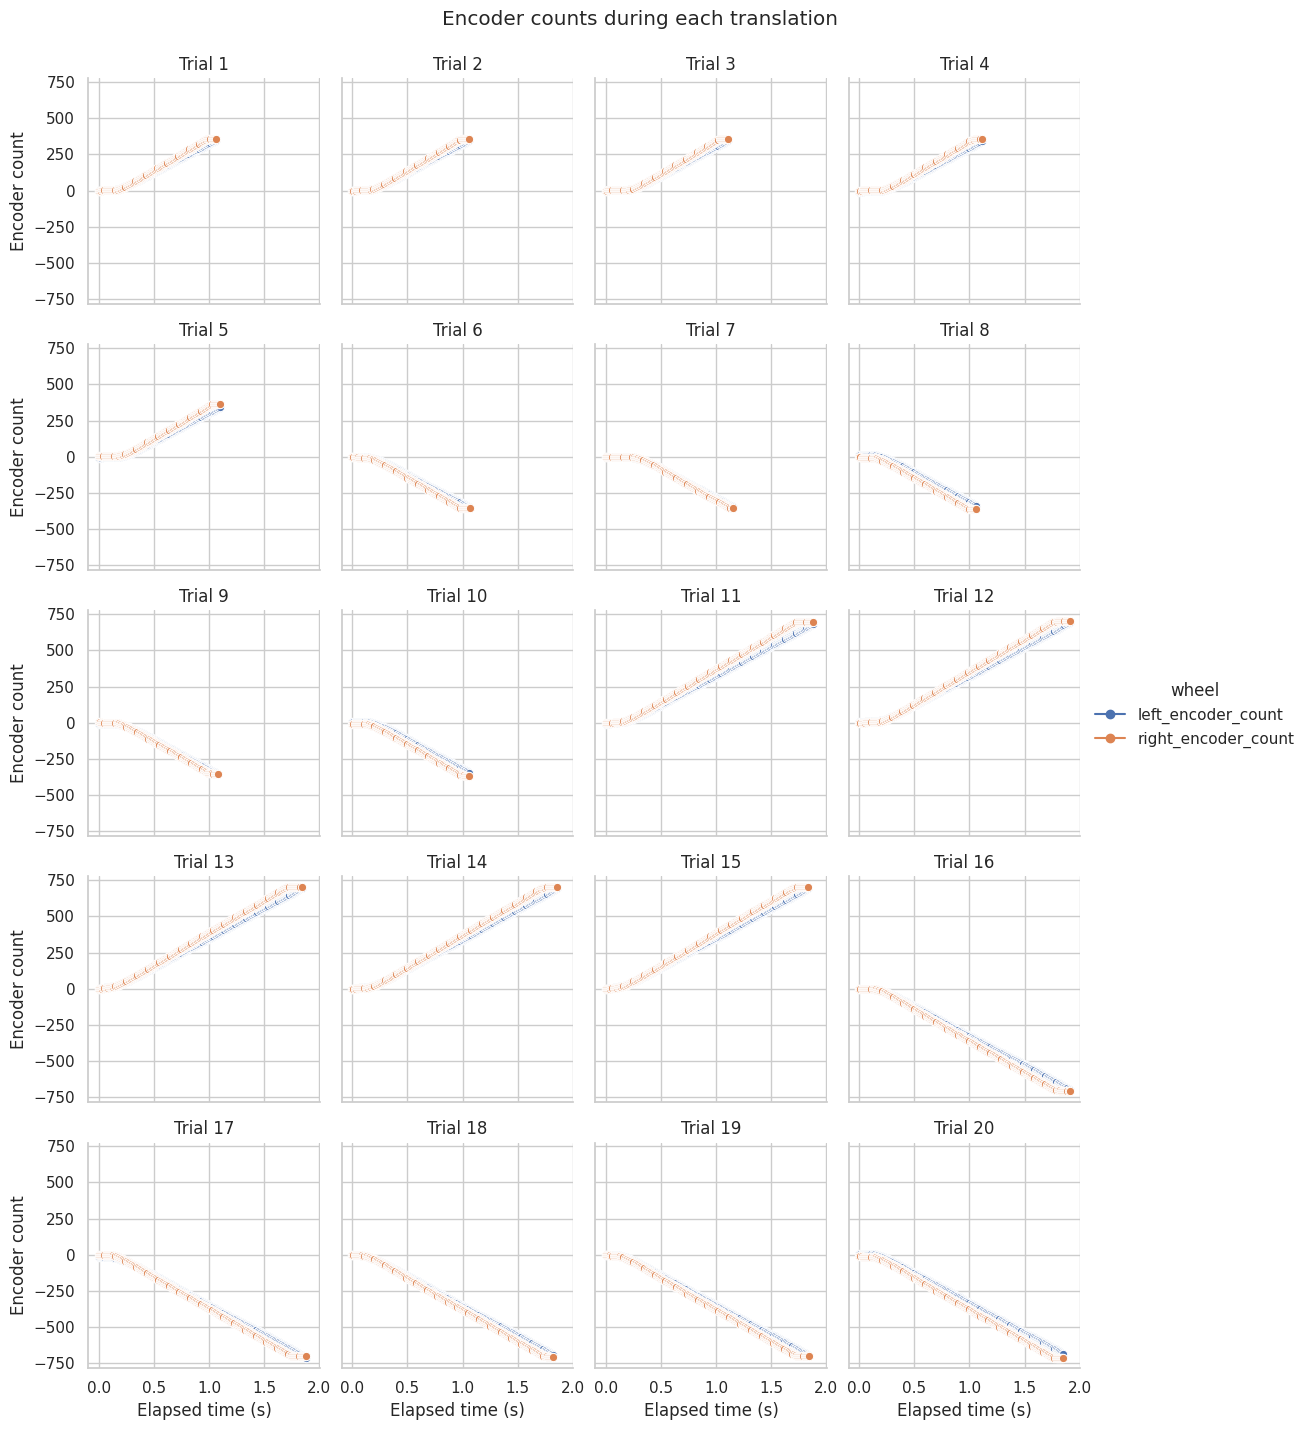

In [11]:

encoder_plot_data = data.melt(
    id_vars=["trial_num", "trial_label", "elapsed_s"],
    value_vars=["left_encoder_count", "right_encoder_count"],
    var_name="wheel",
    value_name="encoder_count",
)

grid = sns.relplot(
    data=encoder_plot_data,
    x="elapsed_s",
    y="encoder_count",
    hue="wheel",
    col="trial_label",
    col_wrap=4,
    kind="line",
    marker="o",
    estimator=None,
    height=2.8,
)

grid.set_axis_labels("Elapsed time (s)", "Encoder count")
grid.set_titles("{col_name}")
grid.figure.suptitle("Encoder counts during each translation", y=1.02)

plt.show()


## 6. Plot the reported x-y paths

This is the trajectory reported by the local odometry model. It is not an external measurement of the physical path, but it can help you see whether the model reported sideways motion.


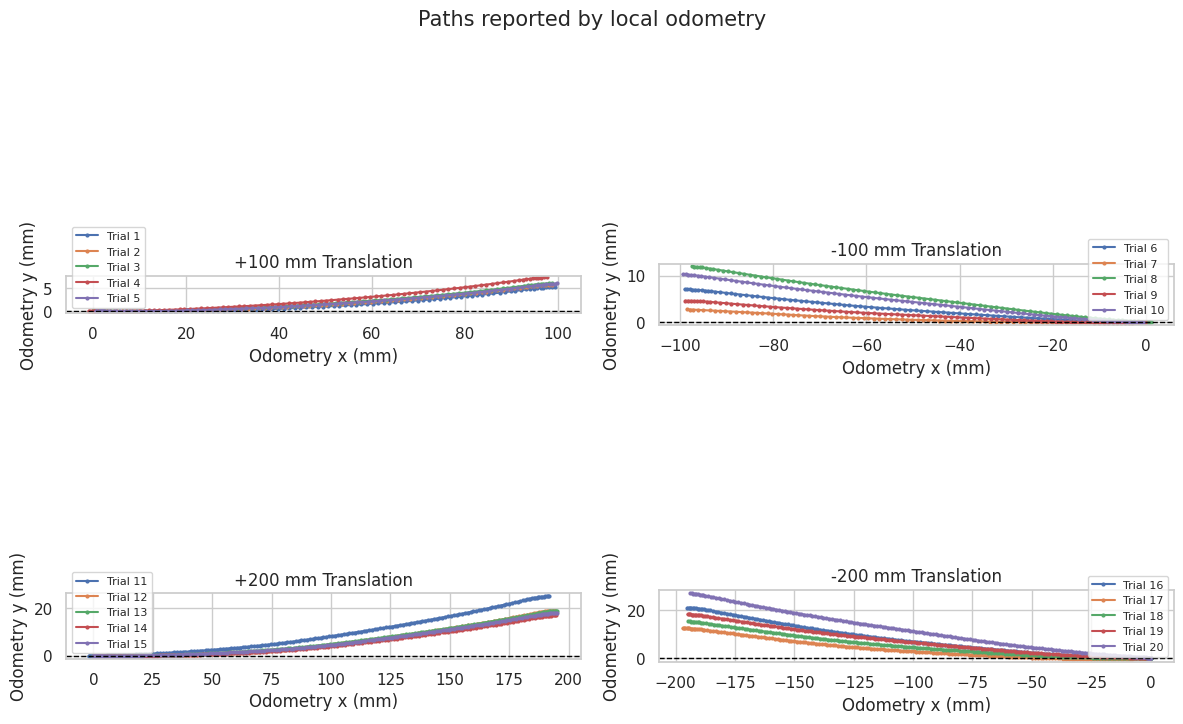

In [13]:

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

conditions = [
    "translation1",
    "translation2",
    "translation3",
    "translation4"
]

titles = [
    "+100 mm Translation",
    "-100 mm Translation",
    "+200 mm Translation",
    "-200 mm Translation"
]

for ax, condition, title in zip(axes.flat, conditions, titles):

    subset = data[data["test_name"] == condition]

    for trial_num, trial_data in subset.groupby("trial_num"):

        trial_data = trial_data.sort_values("sample_time_ms")

        ax.plot(
            trial_data["odometry_x_mm"],
            trial_data["odometry_y_mm"],
            marker="o",
            markersize=2,
            linewidth=1.5,
            label=f"Trial {trial_num}"
        )

    ax.axhline(
        0,
        color="black",
        linewidth=1,
        linestyle="--"
    )

    ax.set(
        title=title,
        xlabel="Odometry x (mm)",
        ylabel="Odometry y (mm)"
    )

    ax.set_aspect("equal", adjustable="box")
    ax.legend(fontsize=8)

plt.suptitle(
    "Paths reported by local odometry",
    fontsize=15
)

plt.tight_layout()
plt.show()


## 7. Extract the initial and final reported positions

The following cell creates one row per trial from the uploaded log. It calculates the reported changes in x, y and heading from the initial and final odometry values.


In [14]:

trial_summary = (
    data.sort_values(["trial_num", "sample_time_ms"])
    .groupby(["test_name", "trial_num"], as_index=False)
    .agg(
        commanded_distance_mm=("commanded_distance_mm", "first"),
        initial_x_mm=("odometry_x_mm", "first"),
        final_x_mm=("odometry_x_mm", "last"),
        initial_y_mm=("odometry_y_mm", "first"),
        final_y_mm=("odometry_y_mm", "last"),
        initial_heading_rad=("odometry_theta_rad", "first"),
        final_heading_rad=("odometry_theta_rad", "last"),
    )
)

# Calculate reported forward/backward displacement
trial_summary["reported_distance_mm"] = (
    trial_summary["final_x_mm"]
    - trial_summary["initial_x_mm"]
)

# Calculate reported sideways displacement
trial_summary["reported_sideways_change_mm"] = (
    trial_summary["final_y_mm"]
    - trial_summary["initial_y_mm"]
)

# Calculate reported heading change
trial_summary["reported_heading_change_deg"] = np.degrees(
    trial_summary["final_heading_rad"]
    - trial_summary["initial_heading_rad"]
)

# Display summary
trial_summary[[
    "test_name",
    "trial_num",
    "commanded_distance_mm",
    "reported_distance_mm",
    "reported_sideways_change_mm",
    "reported_heading_change_deg"
]]


,test_name,trial_num,commanded_distance_mm,reported_distance_mm,reported_sideways_change_mm,reported_heading_change_deg
0,translation1,1,100,99.39,5.29,1.145916
1,translation1,2,100,98.81,5.77,1.145916
2,translation1,3,100,98.80,6.07,1.145916
3,translation1,4,100,98.42,7.36,1.145916
4,translation1,5,100,99.36,6.03,1.718873
5,translation2,6,-100,-98.47,7.08,-1.145916
6,translation2,7,-100,-98.42,2.77,-1.145916
7,translation2,8,-100,-98.43,12.00,-1.145916
8,translation2,9,-100,-98.63,4.64,-0.572958
9,translation2,10,-100,-98.76,10.32,-1.145916


## 8. Enter your physical distance measurements

The timestamped robot log does not contain the distance you measured on the printed sheet. Enter those signed measurements below. Use positive values for forward motion and negative values for reverse motion. Add or remove rows so that the trial numbers match your log. The model radius is the value used when that log was recorded; label each row as `calibration` or `held-back` before comparing results.


In [15]:

# Step 9: Enter physical distance measurements

physical_measurements = pd.DataFrame({
    "trial_num": list(range(1, 21)),

    # Actual measured distances (mm)
    "measured_distance_mm": [
        102, 100, 103, 102, 104,       # translation1: +100 mm
        -103, -104, -102, -102, -102,   # translation2: -100 mm
        208, 208, 208, 209, 210,       # translation3: +200 mm
        -210, -208, -209, -209, -210    # translation4: -200 mm
    ],

    "direction": (
        ["forward"] * 5
        + ["reverse"] * 5
        + ["forward"] * 5
        + ["reverse"] * 5
    ),

    # Model parameters used during data collection
    "model_wheel_radius_mm": [16.0] * 20,
    "model_wheel_separation_mm": [90.0] * 20,

    # Experiment surface
    "surface": ["test surface"] * 20,

    # Reserve one trial per condition for validation
    "data_use": [
        "held-back" if i in [5, 10, 15, 20]
        else "calibration"
        for i in range(1, 21)
    ]
})

# Merge physical measurements with odometry results
comparison = trial_summary.merge(
    physical_measurements,
    on="trial_num",
    validate="one_to_one"
)

# Calculate distance error before calibration
comparison["distance_error_mm"] = (
    comparison["reported_distance_mm"]
    - comparison["measured_distance_mm"]
)

display(comparison[[
    "test_name",
    "trial_num",
    "commanded_distance_mm",
    "reported_distance_mm",
    "measured_distance_mm",
    "distance_error_mm",
    "data_use"
]])


,test_name,trial_num,commanded_distance_mm,reported_distance_mm,measured_distance_mm,distance_error_mm,data_use
0,translation1,1,100,99.39,102,-2.61,calibration
1,translation1,2,100,98.81,100,-1.19,calibration
2,translation1,3,100,98.80,103,-4.20,calibration
3,translation1,4,100,98.42,102,-3.58,calibration
4,translation1,5,100,99.36,104,-4.64,held-back
5,translation2,6,-100,-98.47,-103,4.53,calibration
6,translation2,7,-100,-98.42,-104,5.58,calibration
7,translation2,8,-100,-98.43,-102,3.57,calibration
8,translation2,9,-100,-98.63,-102,3.37,calibration
9,translation2,10,-100,-98.76,-102,3.24,held-back


## 9. Calculate a radius estimate for each calibration trial

Exercise 2 gives the calculation `new radius = old radius × measured distance ÷ reported distance`. The cell applies it only to rows you labelled `calibration`, then shows the individual estimates together with their mean and median.


In [16]:
calibration_rows = comparison.loc[
    comparison["data_use"] == "calibration"
].copy()
calibration_rows["estimated_wheel_radius_mm"] = (
    calibration_rows["model_wheel_radius_mm"]
    * calibration_rows["measured_distance_mm"]
    / calibration_rows["reported_distance_mm"]
)

radius_summary = calibration_rows["estimated_wheel_radius_mm"].agg(
    ["mean", "median"]
)
display(calibration_rows[[
    "trial_num", "measured_distance_mm", "reported_distance_mm",
    "estimated_wheel_radius_mm",
]])
radius_summary


,trial_num,measured_distance_mm,reported_distance_mm,estimated_wheel_radius_mm
0,1,102,99.39,16.420163
1,2,100,98.81,16.192693
2,3,103,98.80,16.680162
3,4,102,98.42,16.581996
5,6,-103,-98.47,16.736062
6,7,-104,-98.42,16.907133
7,8,-102,-98.43,16.580311
8,9,-102,-98.63,16.546690
10,11,208,193.57,17.192747
11,12,208,193.99,17.155523


,estimated_wheel_radius_mm
mean,16.868253
median,16.966817


## 10. Plot measured distance against reported distance

Points on the dashed line indicate agreement. A consistent offset from the line suggests that the wheel-radius value used by the local model may need adjustment. Keep the held-back row out of the radius estimate and use it later to evaluate the selected value.


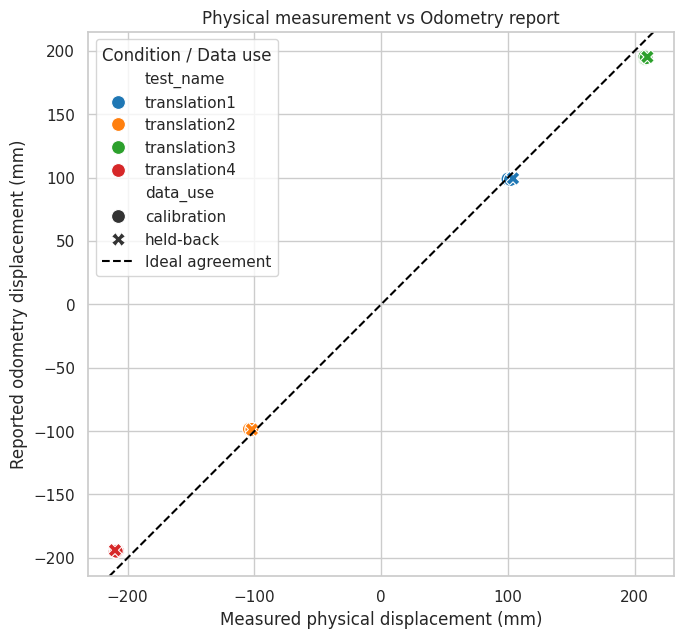

In [18]:

fig, ax = plt.subplots(figsize=(7, 7))

sns.scatterplot(
    data=comparison,
    x="measured_distance_mm",
    y="reported_distance_mm",
    hue="test_name",
    style="data_use",
    palette="tab10",
    s=100,
    ax=ax,
)

# Ideal agreement line
ax.axline(
    (0, 0),
    slope=1,
    color="black",
    linestyle="--",
    label="Ideal agreement"
)

ax.set(
    title="Physical measurement vs Odometry report",
    xlabel="Measured physical displacement (mm)",
    ylabel="Reported odometry displacement (mm)"
)

ax.set_aspect("equal", adjustable="box")
ax.legend(title="Condition / Data use")

plt.tight_layout()
plt.show()


## What to notice

- Do the encoder counts change in the expected direction?
- Does the local odometry report appreciable sideways movement?
- Does the reported distance tend to be larger or smaller than the physical measurement?

Save the notebook with your plots. Base conclusions about physical distance on your independent measurements, not on the commanded value.
